# Statistik / Messunsicherheit

[&larr; Modulübersicht](../00_INTRO.ipynb)

<figure style="text-align:center; margin:1em auto;">
    <img src="img/zielscheibe.png" width=30% />
</figure>

In der Messtechnik spielt neben der Erfassung der Messdaten die **Auswertung der Messdaten** eine sehr wichtige Rolle. In diesem Unterrichtsblock behandeln wir typische Methoden, um Messdaten auszuwerten und die Ergebnisse inkl. Unsicherheiten anzugeben. Zu Beginn werden wir einige **Grundlagen der Statistik** erarbeiten und uns anschliessend dem Thema **Messunsicherheit** zuwenden.

---

## 🎯 Lernziele

- Du kannst statistische Kenngrössen (Mittelwert/Standardabweichung/Konfidenzintervall) bestimmen und verstehst deren Bedeutung.
- Du kannst die Verteilung einer Grösse in einem Histogramm darstellen und das Histogramm korrekt interpretieren.
- Du kannst das Ergebnis einer Messung inkl. der Unsicherheit korrekt angeben.

---

## 📋 Blockinhalt

Es stehen die folgenden Jupyter-Notebooks bereit:

1. Einführung (vorliegendes Notebook)
2. Beispielaufgabe im Unterricht [02_DATENAUSWERTUNG_Unterricht.ipynb](02_DATENAUSWERTUNG_Unterricht.ipynb)
3. Übungsaufgaben [11_DATENAUSWERTUNG_Uebungen.ipynb](11_DATENAUSWERTUNG_Uebungen.ipynb)

---

## 🛠 Voraussetzungen

Das Arbeiten mit 1D- und 2D-Arrays (NumPy) sowie das Einlesen von Daten (Textdateien) mit NumPy solltest du mittlerweile beherrschen.

Reminder zum Einlesen von Textdateien mit NumPy:

```python
data = np.loadtxt(fname = ...,  # Dateiname bzw. Pfad
                  delimiter=None,  # Trennzeichen (Default: Leerzeichen)
                  skiprows=0,  # Anzahl Kopfzeilen ignorieren (Default: 0) 
                  comments='#',  # Zeichen für Kommentarzeilen (Default: #)
                  usecols=None,  # Nur bestimmte Spalten einlesen (Default: alle)
                  ...)
```

---

## 1. Motivation

Messgrössen sind generell immer gewissen Schwankungen (Störungen, Rauschen usw.) unterworfen, d. h. eine "gute" Messung sollte immer aus mehreren Einzelmessungen (Wiederholmessungen) bestehen. In diesem Block wollen wir uns mit der Frage beschäftigen, wie man die erfassten Messdaten auswertet und schliesslich das Ergebnis einer Messung (inkl. Unsicherheit) korrekt angibt.

Damit wir die Überlegungen/Konzepte an einem praktisches Beispiel festmachen können, betrachten wir in diesem Notebook eine aufgezeichnete Strommessung an einem elektrischen Bauteil.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Statistik-Grundlagen

Bevor wir uns dem Thema Messunsicherheit widmen, müssen wir uns einige Grundlagen der Statistik erarbeiten. Dieses Wissen wird Ihnen auch in anderen Themengebieten von Nutzen sein. 

Wenn wir eine Messung durchführen, um eine Messgrösse $x$ zu bestimmen, sind zwei Fragen von Bedeutung:

1) Was ist der **Wert der Messgrösse**?
2) Was ist die **Unsicherheit der Messgrösse**?

Die Bestimmung einer Messgrösse $x$ sollte nie nur durch eine einzige Messung erfolgen, sondern immer anhand mehrerer (möglichst unabhängiger) Einzelmessungen $x_1, x_2, x_3, \dots, x_N$. Es liegt dann eine *Messreihe* mit $N$ Samples (Einzelmessungen) vor, welche analysiert werden kann.

☝🏼 Aus statistischer Sicht stellt die Messreihe eine *Stichprobe* aus der unendlich grossen *Grundgesamtheit* dar. Anhand dieser Stichprobe (Messreihe) können nun die Parameter der (unbekannten) **Grundgesamtheit** abgeschätzt werden.

### 2.1 Verteilungen

Unsere Messreihe besteht aus 100 (wiederholten) Messungen des Stroms in einer elektrischen Schaltung (vgl. Datei `Strommessung.csv`). Als erstes stellen wir die Messreihe als *Punktewolke* dar (auch *Streudiagramm* genannt). Man kann darin z. B. grobe Ausreisser bzw. Anomalien erkennen, es ist jedoch schwierig z. B. etwas über die Verteilung der Daten zu sagen.

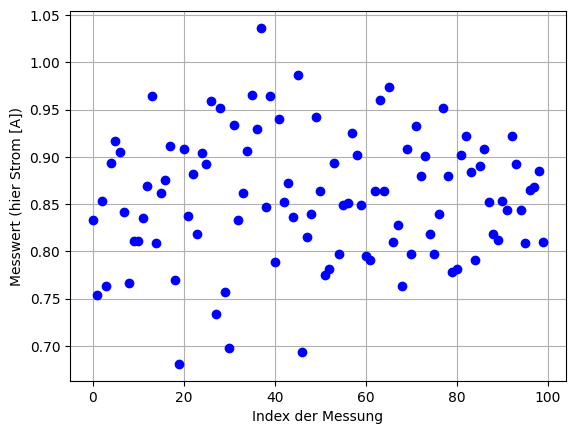

In [3]:
x = np.loadtxt('data/Strommessung.csv', skiprows=1)  # Messdaten
N = len(x)  # Anzahl Samples

plt.plot(x, 'ko', mfc='b', mec='b')
plt.xlabel('Index der Messung')
plt.ylabel('Messwert (hier Strom [A])')
plt.grid()
plt.show()

Um die **Verteilung** der Daten besser visualisieren zu können, bietet sich das **Histogramm** an. Darin sieht man, wie die einzelnen Werte über den Wertebereich verteilt sind. Damit kann beurteilt werden, ob z. B. näherungsweise eine [Normalverteilung](https://de.wikipedia.org/wiki/Normalverteilung) vorliegt oder ob Anomalien in Bezug auf die Verteilung vorliegen (z. B. mehrere "Peaks" etc.). Die Anzahl der Klassen (*Bins*) sollte nicht zu gross und nicht zu klein gewählt werden. Als Richtwert kann der Wert $\sqrt{N}$ verwendet werden (Faustregel).

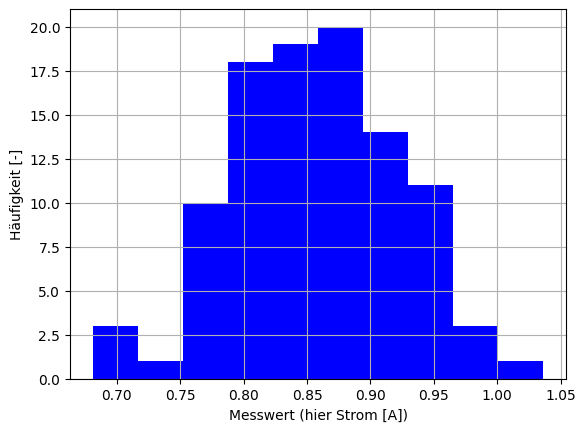

In [4]:
plt.hist(x, bins=10, color='b')  # Histogramm mit 10 Klassen
plt.xlabel('Messwert (hier Strom [A])')
plt.ylabel('Häufigkeit [-]')
plt.grid()
plt.show()

### 2.2 Lage- und Streuungsmasse

#### 2.2.1 Mittelwert

Der **Mittelwert** (auch arithmetisches Mittel oder Durchschnitt genannt) ist für uns das wichtigste Lagemass. Der Mittelwert $\bar{x}$ wird berechnet, indem die Summe aller Samples durch die Anzahl $N$ der Samples dividiert wird.

$$ \bar{x} = \frac{1}{N} \sum_{i} x_i = \frac{x_1 + x_2 + x_3 + \dots + x_N}{N} $$

☝🏼 Der Mittelwert ist i. Allg. der **beste Schätzwert für den wahren (unbekannten) Wert der Messgrösse**. Wir können also die erste der beiden zentralen Fragen (siehe oben) beantworten!

☝🏼 Die Berechnung des Mittelwertes liefert i. Allg. eine beliebige Zahl mit vielen Nachkommastellen (vgl. nachfolgendes Resultat). Was wir aktuell noch nicht sagen können, ist, wie wir das Resutat sinnvoll runden bzw. ausgeben sollten.

In [5]:
x_bar = x.mean()  # Mittelwert (alternativ: np.mean(x))
print(x_bar)

0.8568614965929038


☝🏼  Die Beantwortung der zweiten Frage bzgl. der Unsicherheit der Messgrösse ist etwas komplizierter. Das Streudiagramm (*Punktewolke*) zeigt deutlich, dass die Messwerte stark schwanken und diese Schwankungen werden das Ergebnis in gewisser Weise *unsicher* machen. Im Folgenden werden wir anschauen, wie wir diese Schwankungen *quantifizieren* können.

#### 2.2.2 Standardabweichung

Der Mittelwert alleine sagt nichts aus über die Streuung (Schwankungen) der einzelnen Werte. Als Mass für die Streuung wäre z. B. die mittlere absolute Abweichung $e$, also die durchschnittliche Abweichung der Einzelmessungen vom Mittelwert, geeignet:

$$ e = \frac{1}{N} \sum_{i} \vert x_i-\bar{x} \vert $$

Aufgrund des Betrags hat die mittlere absolute Abweichung aber ungünstige Eigenschaften ("Knickstelle") und daher hat sich die **Standardabweichung** $s$ als wichtigstes Streuungsmass etabliert.

$$ s = \sqrt{\frac{1}{N-1} \sum_{i} \left( x_i-\bar{x} \right)^2}  $$

Das Quadrat der Standardabweichung, also $s^2$, wird als **Varianz** bezeichnet.

☝🏼 NumPy stellt die Methode `std()` zur Verfügung, um die Standardabweichung zu berechnen. Wird die Standardabweichung einer Stichprobe berechnet (Nenner $N-1$), so muss der Parameter `ddof = 1` verwendet werden. Defaultmässig wird `ddof = 0` verwendet, d. h. die Standardabweichung wird mit dem Nenner $N$ berechnet (dies wird gemacht, wenn man die Standardweichung einer Grundgesamtheit berechnet).

In [6]:
s = x.std(ddof=1)  # Stichprobenstandardabweichung
print(s)

0.06747874874678095


Mit Mittelwert und Standardabweichung ist die Verteilung eindeutig definiert, wenn man davon ausgeht, dass es sich um eine **Normalverteilung** handelt. Die Normalverteilung (auch *Gausssche Glockenkurve* genannt) ist die wichtigste Verteilung in der Natur/Technik, da viele Grössen zumindest näherungsweise normalverteilt sind. Dies kommt daher, dass in komplexen Systemen viele Einzeleffekte zusammenkommen und die Messgrösse beeinflussen. Auch wenn einzelne dieser Effekte nicht normalverteilt sind, so ergibt sich durch das Zusammenspiel aller Einzeleffekte schliesslich in guter Näherung eine Normalverteilung (vgl. [zentraler Grenzwertsatz](https://de.wikipedia.org/wiki/Zentraler_Grenzwertsatz)).

<figure style="text-align:center; margin:1em auto;">
    <img src="img/normal_dist.svg" width=80%/>
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Wahrscheinlichkeitsdichtefunktion der Normalverteilung
    </figcaption>
</figure>

Im Zusammenhang mit der theoretischen Normalverteilung wird der Mittelwert mit $\mu$ (My) und die Standardabweichung mit $\sigma$ (Sigma) bezeichnet (und entsprechend $\sigma^2$ als Varianz). Innerhalb von einer Standardabweichung ($\pm\sigma$) befinden sich ca. 68&nbsp;% aller Werte, innerhalb von $\pm 2 \sigma$ ca. 95&nbsp;% usw.

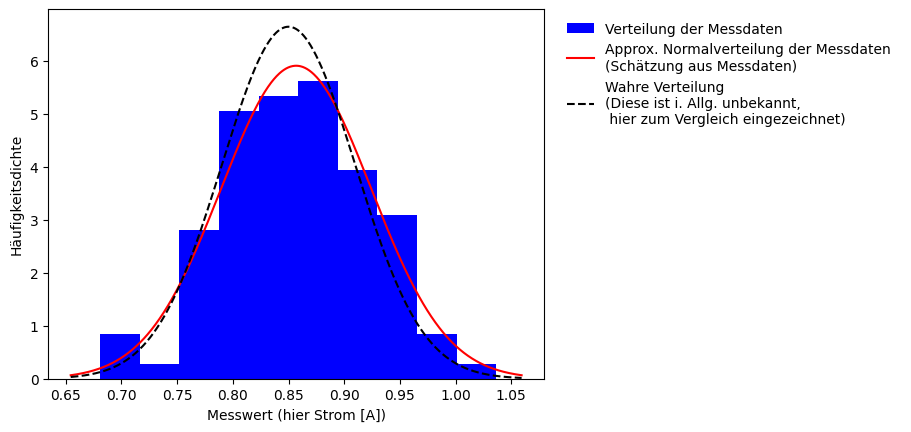

In [7]:
x_ = np.linspace(x_bar-3*s, x_bar+3*s, 1000)
pdf = np.exp(-np.square(x_-x_bar)/(2*s**2))/(np.sqrt(2*np.pi*s**2))  # Normalverteilung
pdf_true = np.exp(-np.square(x_-0.85)/(2*0.06**2))/(np.sqrt(2*np.pi*0.06**2))  # Normalverteilung

plt.hist(x, density=True, color='b', label='Verteilung der Messdaten')
plt.plot(x_, pdf, 'r', label='Approx. Normalverteilung der Messdaten \n(Schätzung aus Messdaten)')
plt.plot(x_, pdf_true, 'k--', label='Wahre Verteilung \n(Diese ist i. Allg. unbekannt,\n hier zum Vergleich eingezeichnet)')
plt.xlabel('Messwert (hier Strom [A])')
plt.ylabel('Häufigkeitsdichte')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

Wir können den Mittelwert und z. B. das 95&nbsp;%-Band ($\pm 2 \sigma$) auch in unserem Streudiagramm einzeichnen, um den Sachverhalt zu verdeutlichen. Erwartungsgemäss liegen dabei ca. 5&nbsp;% der Samples ausserhalb des Bandes.

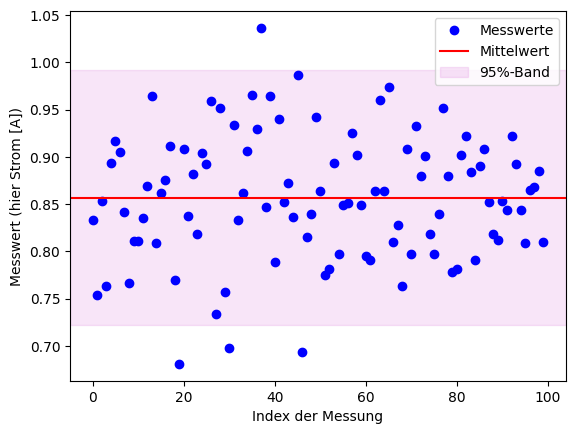

In [20]:
fig, ax = plt.subplots()
ax.plot(x, 'ko', mfc='b', mec='b', label='Messwerte')
ax.axhline(x_bar, color='r', label='Mittelwert')
ax.axhspan(x_bar-2*s, x_bar+2*s, color='m', alpha=0.1, label='95%-Band')
ax.set_xlabel('Index der Messung')
ax.set_ylabel('Messwert (hier Strom [A])')
ax.legend()
plt.show()

#### 2.2.3 Standardabweichung des Mittelwertes

Eine interessante Frage lautet nun: **Wie stark würde der Mittelwert streuen, wenn wir die obige Stichprobe (Messung) wiederholen würden?** 

Um diese Frage beantworten zu können, müssen wir also die *Streuung des Mittelwertes* betrachten, d.&nbsp;h. uns interessiert die **Standardabweichung des Mittelwertes** (nicht diejenige der Einzelmessungen, die wir oben berechnet haben). Die Standardabweichung des Mittelwertes kann gemäss $\dfrac{s}{\sqrt{N}}$ abgeschätzt werden und ist umso kleiner,
- je kleiner die Standardabweichung der Einzelmessungen ist und
- je grösser der Stichprobenumfang $N$ ist, d.&nbsp;h. je mehr Einzelmessungen vorliegen.

In [8]:
print(s/np.sqrt(N))  # Standardabweichung des Mittelwertes

0.006747874874678095


#### 2.2.4 Konfidenzintervall

Mit der obigen Standardabweichung des Mittelwertes können nun sogenannte **Konfidenzintervalle** (*Confidence Interval*, kurz *CI*) gebildet werden. Ein Konfidenzintervall (auch Vertrauensintervall genannt) gibt den Wertebereich an, der mit einer gewissen Wahrscheinlichkeit den "wahren" Wert einschliesst. Diese Wahrscheinlichkeit wird durch das Konfidenzniveau (Vertrauensniveau) festgelegt und entspricht der nominalen Überdeckungswahrscheinlichkeit. 

Dabei wird die Standardabweichung des Mittelwertes nun je nach Vertrauensniveau mit einem Faktor $t$ multipliziert (68&nbsp;% $\rightarrow t \approx 1$, 95&nbsp;% $\rightarrow t \approx 2$, ...).

$$ CI = \bar{x} \pm t \cdot \frac{s}{\sqrt{N}} $$

☝🏼 Wir werden üblicherweise mit dem 95&nbsp;%-Konfidenzniveau arbeiten. Der obige Faktor $t$ nimmt dann näherungsweise den Wert 2 an.

In [9]:
print(f"95%-Konfidenzintervall: {x_bar:.3f} +/- {2*s/np.sqrt(N):.3f} A")

95%-Konfidenzintervall: 0.857 +/- 0.013 A


Das Konfidenzintervall ist folgendermassen zu interpretieren: **Das angegebene Konfidenzintervall enthält den wahren Wert mit einer Wahrscheinlichkeit von 95&nbsp;%.** Mit der Angabe des Konfidenzintervalls können wir also ausdrücken, wie sicher ("genau") der Mittelwert ist.

Um die Bedeutung des Konfidenzintervalls noch besser illustrieren zu können, wiederholen wir die obige Messung (Stichprobe) in einer Simulation 60-mal und berechnen jeweils das 95&nbsp;%-Konfidenzintervall. Wir erkennen, das im Schnitt etwa 3 Konfidenzintervalle von den 60 den wahren Wert nicht enthalten, was dem 95&nbsp;%-Vertrauensniveau entspricht.

☝🏼 Wir können das hier nur überprüfen, weil wir den wahren Wert $I = 0.85 \, \mathrm{A}$ kennen. Bei einer realen Messung ist dies natürlich nicht der Fall. Ebenfalls können wir eine reale Messung auch nicht einfach in einer Simulation wiederholen!

☝🏼 Um Konfidenzintervalle oder allgemein Fehlerbalken von Messpunkten plotten zu können, bietet Matplotlib den Plottyp `errorbar(x, y, yerr, ...)` an, wobei mit `yerr` die Grösse der Fehlerbalken definiert werden können.

In [10]:
x_sim_bar = []
x_sim_CI = []
for i in range(60):
    x_sim = np.random.normal(loc=0.85, scale=0.06, size=N)  # Stichprobe simulieren
    x_sim_bar.append(x_sim.mean())  # Mittelwert
    s_sim = x_sim.std(ddof=1)
    x_sim_CI.append(2*s_sim/np.sqrt(N))  # 95%-Konfidenzintervall

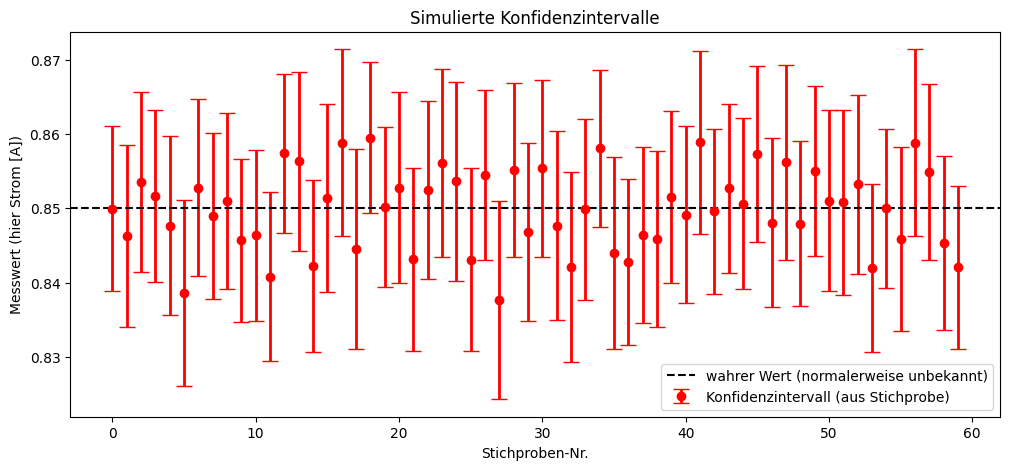

In [11]:
fig, ax = plt.subplots(figsize=(12,5))
ax.errorbar(range(60), x_sim_bar, x_sim_CI, fmt='ro', linewidth=2, capsize=6)
ax.axhline(0.85, color='k', ls='--')
ax.set_xlabel('Stichproben-Nr.')
ax.set_ylabel('Messwert (hier Strom [A])')
ax.legend(['wahrer Wert (normalerweise unbekannt)', 'Konfidenzintervall (aus Stichprobe)'])
ax.set_title('Simulierte Konfidenzintervalle')
plt.show()

## 3. Messunsicherheit

Eine Grösse (Messgrösse) kann nie exakt bestimmt werden, da einerseits **zufällige Schwankungen** der Grösse vorliegen und andererseits **systematische Abweichungen** zum (unbekannten) wahren Wert vorliegen. Eine *genaue* Messung weist sowohl eine hohe *Präzision* (= kleine Streuung) als auch eine hohe *Richtigkeit* (= keine systematische Abweichung) auf. Die folgende Abbildung illustriert dies sehr schön.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/genauigkeit.png" width=90% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Genauigkeit = Richtigkeit + Präzision <a href="https://www.peterjohann-consulting.de/genauigkeit-praezision-oder-richtigkeit/">[Quelle]</a>
    </figcaption>
</figure>

Es gibt verschiedene Möglichkeiten, um mit Messunsicherheiten umzugehen bzw. diese zu bestimmen. Es gibt eine Norm bzw. einen [ISO/BIPM-Leitfaden](https://de.wikipedia.org/wiki/GUM_(Norm)), welcher die Bestimmung von Messunsicherheiten behandelt (würde aber über den Umfang dieses Moduls hinausgehen). Wenn du in deiner Firma mit Messunsicherheiten zu tun hast, informier dich über das interne Vorgehen diesbezüglich.

☝🏼 Du wirst feststellen, dass im Folgenden im Prinzip wieder diesselben Grössen wie oben (Grundlagen) vorkommen, nun einfach z. T. unter anderen Namen bzw. im Zusammenhang mit der Messunsicherheitsbestimmung.

**Systematische Abweichungen** können im Idealfall vermieden oder korrigiert werden, sodass im Wesentlichen nur **zufällige/statistische Abweichungen** auftreten. Mit den oben gelernten Konzepten/Verfahren können wir mit diesen umgehen. Im Folgenden gehen wir also davon aus, dass keine systematische Abweichungen vorliegen bzw. diese vollständig korrigiert wurden.

### 3.1 Standardunsicherheit

Im Zusammenhang mit der Messunsicherheitsbestimmung sprechen wir von Standardunsicherheiten $u$. Das sind Standardabweichungen, d.&nbsp;h. sie beziehen sich immer auf das 68&nbsp;%-Vertrauensniveau. 

Werden $N$ Wiederholmessungen durchgeführt, ist die Standardunsicherheit $u$ der Messgrösse als Standardabweichung des Mittelwertes definiert.

$$ u = \frac{s}{\sqrt{N}} $$

In [13]:
u_1 = s/np.sqrt(N)  # Unsicherheit aus Wiederholmessungen [A]
print(u_1)

0.006747874874678095


Treten z.&nbsp;B. weitere Unsicherheiten auf (z.&nbsp;B. Unsicherheiten des Messgerätes, Unsicherheiten aus Kalibrierungen, ...) werden die einzelnen Beiträge quadratisch addiert. Wichtig ist, dass alle Unsicherheitsbeiträge Standardunsicherheiten sind, d.&nbsp;h. auf dem 68&nbsp;%-Vertrauensniveau liegen.

$$ u = \sqrt{u_1^2 + u_2^2 + ...} $$

In unserem Fall finden wir im Kalibrierprotokoll des verwendeten Messgerät eine zusätzliche Unsicherheit, die mit 1&nbsp;mA angegeben ist (Standardunsicherheit).

☝🏼 In vielen Fällen liegen Genauigkeitsangaben nicht als Standardunsicherheiten vor, sondern z.&nbsp;B. als Fehlergrenzen ($\pm a$). In solchen Fällen kann eine Gleichverteilung angenommen werden und diese gemäss nachfolgender Beziehung in eine Normalverteilung (Standardunsicherheit) umgerechnet werden. Die untenstehende Abbildung illustriert dies anschaulich.

$$ u = \frac{a}{\sqrt{3}} $$

<figure style="text-align:center; margin:1em auto;">
    <img src="img/conversion.svg" />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Rechteckverteilung in Normalverteilung "umwandeln"
    </figcaption>
</figure>

In [14]:
u_2 = 0.001  # zusätzliche Unsicherheit aus Kalibrierprotokoll [A]

u = np.sqrt(u_1**2 + u_2**2)  # Gesamtstandardunsicherheit [A]
print(u)

0.006821569857760889


### 3.2 Erweiterte Messunsicherheit

Die obigen Standardunsicherheiten beziehen sich immer auf das 1-Sigma-Niveau, d. h. auf das 68&nbsp;%-Vertrauensniveau. Das endgültige Ergebnis wird typischerweise auf dem 95&nbsp;%-Vertrauensniveau angegeben, d. h. wir multiplizieren die Standardunsicherheit mit einem Erweiterungsfaktor $k = 2$ (oder $k = 3$ für 99&nbsp;%-Vertrauensniveau etc.).

$$ U = k \cdot u $$

In [15]:
k = 2  # Erweiterungsfaktor für 95%-Vertrauensniveau
U = k * u  # erweiterte Messunsicherheit
print(U)

0.013643139715521778


Schliesslich können wir das Resultat zusammen mit der Unsicherheit angeben (natürlich mit Einheiten), wobei man immer das Vertrauensniveau (typischerweise den Erweiterungsfaktor $k$) mitangeben muss.

$$ \bar{x} \pm U \quad (k = \ldots) $$

☝🏼 Faustregel zum Runden: Die erweiterte Messunsicherheit wird üblicherweise auf zwei signifikante Stellen gerundet und das Messergebnis auf gleich viele Stellen gerundet. Bsp.:

$$ I = 0.857 \pm 0.014 \text{ A} \quad (k = 2) $$

In [16]:
print(f"Strom I = {x_bar:.3f} +/- {U:.3f} A  (k = {k})")

Strom I = 0.857 +/- 0.014 A  (k = 2)


---

## 💡 Verständnisfragen

- Erkläre das Streuungsmass *Standardabweichung des Mittelwertes* in einfachen Worten.
- Was bedeutet der Begriff *Vertrauensniveau*?
- Erkläre den Unterschied zwischen *Richtigkeit* und *Präzision* im Zusammenhang mit der Messgenauigkeit.
- Erkläre den Unterschied zwischen *systematischen* und *zufälligen/statistischen* Abweichungen.

---

## A. Anhang

> ☝🏼 Nachfolgend sind weiterführende Informationen aufgeführt, die allerdings nicht zum Stoffumfang des Moduls gehören und daher als optional zu betrachten sind.

### A.1 Messunsicherheit einer indirekten/berechneten Grösse

In vielen Fällen kann eine Grösse nicht direkt gemessen werden, sondern wird (indirekt) aus anderen Grössen bestimmt. Es liegt dann eine Beziehung (Funktion $f$) zwischen einer oder mehreren Einflussgrössen $x_i$ und der Zielgrösse $y$ vor.

$$ y = f(x_1, x_2, \dots) $$

Als Beispiel wollen wir hier die Leistung berechnen, die "verbraucht" wird, wenn der obige Strom durch einen 12 $\Omega$ Widerstand fliesst. Die elektrische Leistung eines Widerstandes wird bekanntlich berechnet mit:

$$ P = R \cdot I^2 $$

Vom Widerstand sind Nominalwert (12 $\Omega$) und Toleranz (5%) gegeben.

In [17]:
R = 12  # Nominalwert des Widerstandes (gegeben)
I = x_bar  # Mittelwert der Strommessung (von oben)

#### A.1.1 Resultat berechnen

Das Resultat der Zielgrösse $\bar{y}$ wird anhand der Mittelwerte $\bar{x_1}, \bar{x_2}, \dots$ gebildet.

$$ \bar{y} = f(\bar{x_1}, \bar{x_2}, \dots) $$

In [18]:
P = R * I**2  # Leistung [W]
print(P)

8.81053949212117


#### A.1.2 Standardunsicherheiten bestimmen

Nun werden die Standardunsicherheiten der einzelnen Messgrössen gebildet. Von der Strommessung haben wir diese bereits oben berechnet. Vom Widerstand ist nur die Toleranz (5&nbsp;%) gegeben ohne weitere Angaben. Wir interpretieren dies als Fehlergrenze, d. h. der wahre Widerstandswert kann irgendwo im Bereich +/-5&nbsp;% liegen, also im Intervall 11.4 $\Omega$ - 12.6 $\Omega$. Dies entspricht einer Rechteckverteilung und muss in die Normalverteilung umgerechnet werden (siehe oben).

In [19]:
u_I = u  # Standardunsicherheit Strom (siehe oben)

a = 0.05 * R  # Halbbreite der Rechteckverteilung (5%)
u_R = a / np.sqrt(3)  # Standardunsicherheit Widerstand
print(u_R)

0.3464101615137755


#### A.1.3 Kombinierte Messunsicherheit bestimmen

Die Unsicherheit von $\bar{y}$ wird gemäss des *Fehlerfortpflanzungsgesetzes* berechnet, wobei die einzelnen Standardunsicherheiten $u_{x_i}$ der Einflussgrössen $x_i$ sowie deren Ableitungen $\frac{dy}{dx_i}$ benötigt werden. Die kombinierte Messunsicherheit ergibt sich als gewichtete Summe der einzelnen Unsicherheiten.

$$ u_y = \sqrt{\sum_{i}\left(\frac{dy}{dx_i}\cdot u_{x_i}\right)^2} $$

Konkret für unsere Leistungsmessung sieht das folgendermassen aus:

$$ u_P = \sqrt{\left(\frac{dP}{dR}\cdot u_R\right)^2 + \left(\frac{dP}{dI}\cdot u_I\right)^2} $$

In [20]:
dP_dR = I**2  # Ableitung nach R
dP_dI = 2*I*R  # Ableitung nach I

u_P = np.sqrt((dP_dR * u_R)**2 + (dP_dI * u_I)**2)  # kombinierte Messunsicherheit
print(u_P)  # Standardunsicherheit Leistung

0.2904607201756386


#### A.1.4 Erweiterte Messunsicherheit bestimmen

Danach wird wiederum die erweiterte Messunsicherheit gemäss des gewählten Vertrauensniveaus berechnet.

$$ U = k \cdot u_y $$

Schliesslich können wir das Resultat zusammen mit der Unsicherheit angeben (natürlich mit Einheit und Vertrauensniveau).

$$ \bar{y} \pm U \quad (k = \ldots) $$

In [21]:
U_P = k * u_P
print(f"Leistung P = {P:.2f} +/- {U_P:.2f} W  (k = {k})")

Leistung P = 8.81 +/- 0.58 W  (k = 2)


### A.2 Median & Quartile

Um Verteilungen vergleichen zu können, können auch andere Masse (als Mittelwert und Standardabweichung) hilfreich sein, unter anderem z. B. der **Median**. Der Median ist der Wert, welcher die Messwerte in zwei Hälften unterteilt (wenn man alle Messwerte der grösse nach sortiert, ist der Median der Wert, der genau in der Mitte liegt). Daneben werden Quartile definiert, welche mit dem Median zusammen die Daten in vier gleich grosse Teile unterteilen (vgl. nachfolgende Abbildung). Diese Masse haben den grossen Vorteil, dass sie gegenüber Ausreissern sehr robust/unanfällig sind. In der Technik spielen Median/Quartile etc. allerdings eine untergeordnete Rolle.

<figure style="text-align:center; margin:1em auto;">
    <img src="img/boxplot.png" width=60% />
    <figcaption style="font-size:0.9em; font-style:italic; margin-top:0.4em;">
        Abb.: Boxplot <a href="https://de.wikipedia.org/wiki/Empirisches_Quantil#Quartil">[Quelle]</a>
    </figcaption>
</figure>

In [22]:
x_median = np.median(x)
print(x_median)

0.8532518125630798


Wie oben bereits gezeigt, bietet sich der *Boxplot* sehr gut an, um eine Verteilung kompakt zu visualisieren und allenfalls mit einer anderen Verteilung zu vergleichen.

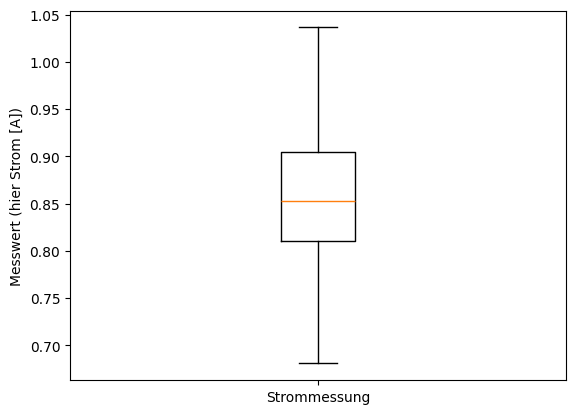

In [29]:
plt.boxplot(x, tick_labels=['Strommessung'])
plt.ylabel('Messwert (hier Strom [A])')
plt.show()

Eng verwandt mit dem Boxplot ist der [Violinplot](https://en.wikipedia.org/wiki/Violin_plot) (Geigendiagramm), der eine Art Kombination von Histogramm & Boxplot darstellt.